# Error Review: False Positives and False Negatives

Inspect model errors from the selected classifier test predictions. This notebook helps decide what clips to listen to next.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

from pathlib import Path

def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "workspace").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing workspace/ and scripts/. Run this notebook from inside the StromPetrels project.")

PROJECT_ROOT = find_project_root()
MODELS = PROJECT_ROOT / "workspace" / "models"
PREDICTIONS = MODELS / "storm_petrel_classifier_C_test_predictions.csv"
THRESHOLD = 0.5

pd.set_option("display.max_colwidth", 160)

In [4]:
pred = pd.read_csv(PREDICTIONS)
pred["score"] = pd.to_numeric(pred["score"])
pred["true_label"] = pd.to_numeric(pred["true_label"])
pred["predicted_label"] = (pred["score"] >= THRESHOLD).astype(int)

false_positives = pred[(pred.true_label == 0) & (pred.predicted_label == 1)].sort_values("score", ascending=False)
false_negatives = pred[(pred.true_label == 1) & (pred.predicted_label == 0)].sort_values("score")

print(f"False positives: {len(false_positives)}")
print(f"False negatives: {len(false_negatives)}")
display(false_positives)
display(false_negatives)

False positives: 3
False negatives: 1


,file,class_folder,true_label,score,predicted_label
52,D:\Documents\StromPetrels\workspace\birdnet_dataset\test\Background\background_00368_011_210522_184504_0022397350.wav,Background,0,4.211189,1
33,D:\Documents\StromPetrels\workspace\birdnet_dataset\test\Background\background_00203_011_210522_184504_0032778774.wav,Background,0,3.617769,1
22,D:\Documents\StromPetrels\workspace\birdnet_dataset\test\Background\background_00157_064_210628_225602_0009295035.wav,Background,0,1.337675,1


,file,class_folder,true_label,score,predicted_label
87,D:\Documents\StromPetrels\workspace\birdnet_dataset\test\storm_petrel\00103_064_210531_221134_0012918000.wav,storm_petrel,1,-0.127208,0


## Listen to Error Clips

background_00368_011_210522_184504_0022397350.wav
class_folder=Background true=0 score=4.2112


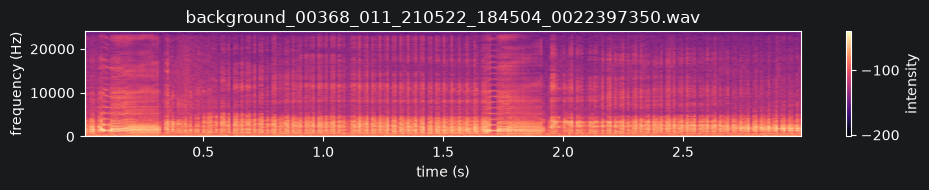

background_00203_011_210522_184504_0032778774.wav
class_folder=Background true=0 score=3.6178


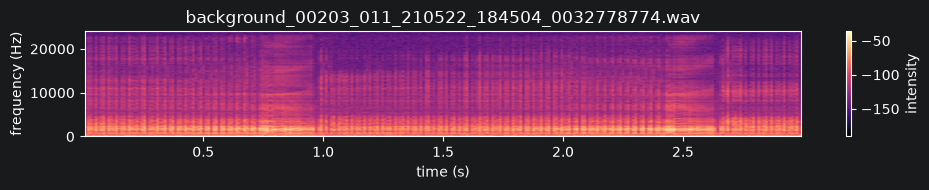

background_00157_064_210628_225602_0009295035.wav
class_folder=Background true=0 score=1.3377


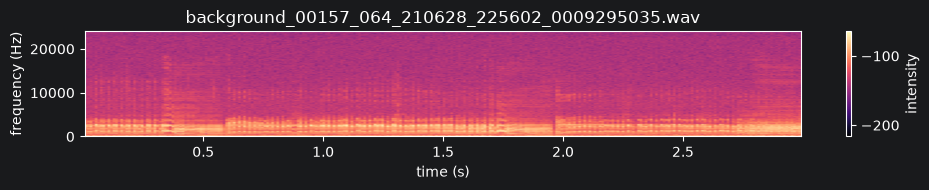

00103_064_210531_221134_0012918000.wav
class_folder=storm_petrel true=1 score=-0.1272


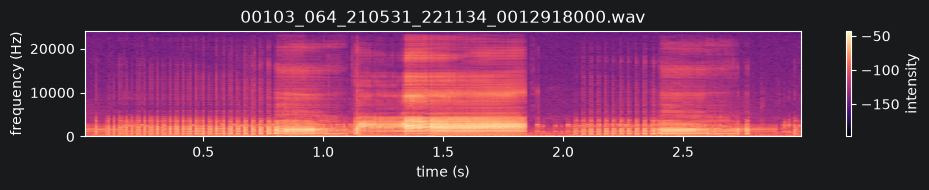

In [5]:
def show_clip(row):
    path = Path(row["file"])
    data, rate = sf.read(path)
    if getattr(data, "ndim", 1) > 1:
        data = data.mean(axis=1)
    print(path.name)
    print(f"class_folder={row['class_folder']} true={row['true_label']} score={row['score']:.4f}")
    display(Audio(data, rate=rate))
    plt.figure(figsize=(10, 2))
    plt.specgram(data, Fs=rate, NFFT=1024, noverlap=512, cmap="magma")
    plt.colorbar(label="intensity")
    plt.title(path.name)
    plt.xlabel("time (s)")
    plt.ylabel("frequency (Hz)")
    plt.tight_layout()
    plt.show()

for _, row in false_positives.head(5).iterrows():
    show_clip(row)

for _, row in false_negatives.head(5).iterrows():
    show_clip(row)

After listening, decide whether each error is a true model mistake or a label problem. If many false positives are real Storm Petrel calls, fix the labels before training again.